In [21]:
import pandas as pd
df = pd.read_csv("../data/iris.csv")

In [22]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [23]:
df.shape

(150, 5)

In [24]:
df.columns

Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='str')

In [25]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [26]:
df.isnull().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

In [27]:
df.duplicated().sum()

np.int64(1)

In [28]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [29]:
X = df.drop(columns=["species"])

y = df["species"]

In [30]:
print("Feature shape: ", X.shape)
print("Target shape: ", y.shape)

print("Feature names: ", X.columns.tolist())
print("Target names: ", y.unique())

Feature shape:  (150, 4)
Target shape:  (150,)
Feature names:  ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
Target names:  <StringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str


In [31]:
y.value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [32]:
y.value_counts(normalize=True)

species
setosa        0.333333
versicolor    0.333333
virginica     0.333333
Name: proportion, dtype: float64

# Exploratory Data Analysis(EDA)

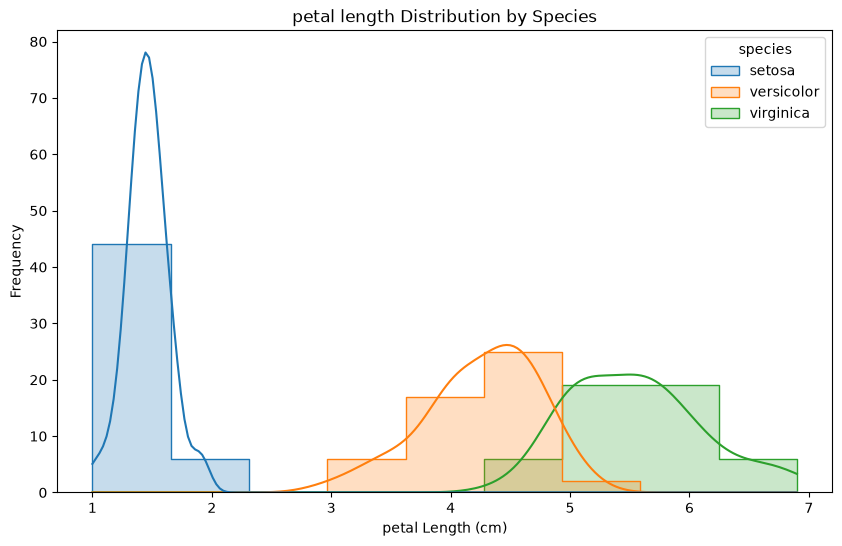

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))
sns.histplot(
    data=df,
    x="petal_length",
    hue="species",
    kde=True,
    element="step",
)
plt.title("petal length Distribution by Species")
plt.xlabel("petal Length (cm)")
plt.ylabel("Frequency")

plt.show()

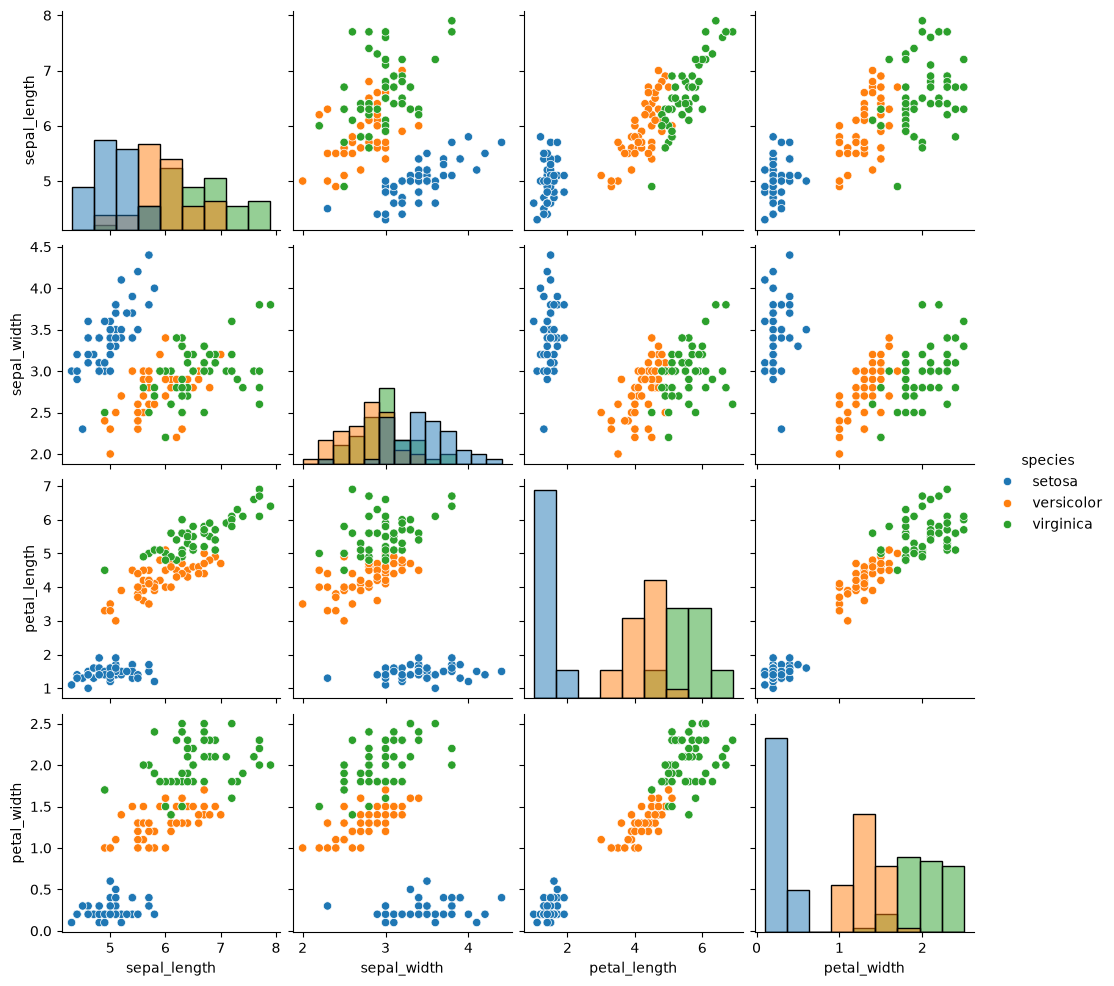

In [34]:
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.show()

Pairplot Observation
The pairplot shows clear clustering of the three iris species. Setosa forms a distinct cluster and is easily separable from the other species. Petal length and petal width provide the strongest separation between classes, while sepal measurements show greater overlap. Versicolor and Virginica exhibit some overlap but remain largely distinguishable. These observations suggest that the dataset is well suited for classification tasks.

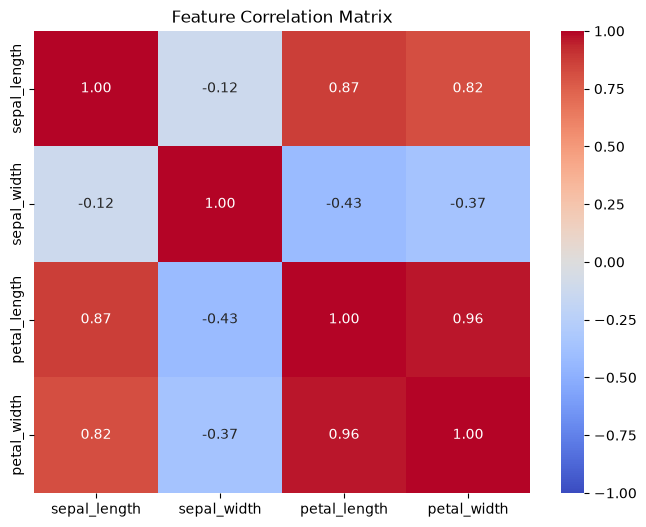

In [35]:
correlation_matrix = X.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Feature Correlation Matrix")

plt.show()

# Correlation Matrix asks:

"How strongly are the features related to each other?"

For example:

 
If petal_length increases,

does petal_width also increase?

Correlation goes from:

 
-1 → Perfect negative relationship

0 → No relationship

+1 → Perfect positive relationship

# as preview
1, petal_length ↔ petal_width = 0.96
means like "Flowers with longer petals usually aslo have wider petals  so it has strong positive Relationship

2, sepal_length ↔ petal_length = 0.87
means like "Flowers with longer sepals tend to have longer petals
so it has also positive and very strong relationship

3, sepal_width ↔ petal_length = -0.43
means like As petal length invrease sepal width tends to decrease somewhat and negative correlation also like Not a perfect relationship, but there is a tendency

4, sepal_length ↔ sepal_width = -0.12
means like almost no linear relationship
knowing sepal length doesn't tell us much about sepal width , very close to zero

# Prepare Data for Machine Learning

In [36]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [37]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\n Training labels:")
print(y_train.value_counts())

print("\n Testing labels:")
print(y_test.value_counts())

Training features: (120, 4)
Testing features: (30, 4)

 Training labels:
species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64

 Testing labels:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


In [40]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

Logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])
Logistic_pipeline.fit(X_train, y_train)
y_pred_logistic = Logistic_pipeline.predict(X_test)


# Now we're about to Train and compare models


Meet our two models

We're going to compare:

Logistic Regression
Decision Tree Classifier

Why these two?

Because they learn patterns in different ways. Comparing them will help you understand how algorithm choice affects model performance.

Model A: Logistic Regression

Despite its name, Logistic Regression is commonly used for classification.

It learns relationships between input features and class probabilities.

For our Iris dataset, it uses four flower measurements to estimate the probabilities of the three species.

For example, a prediction might look conceptually like this:

Species	Predicted probability
Setosa	0.95
Versicolor	0.03
Virginica	0.02

The model would predict Setosa because it has the highest estimated probability.

These probabilities are estimates, not guarantees of correctness.

Its strength: Logistic Regression provides a relatively simple model that often generalizes well when class boundaries can be approximated by suitable linear decision boundaries.

Its limitation: It may struggle when the relationship between the features and the classes requires more complex decision boundaries.

Model B: Decision Tree

A Decision Tree learns a sequence of feature-based decisions.

Imagine a simplified tree:

          Petal length < 2.5?
             /          \
           Yes           No
            |             |
          Setosa     Petal width < 1.8?
                       /          \
                     Yes           No
                      |             |
                 Versicolor      Virginica

This is an illustrative example, not a tree we've trained yet.

The actual tree will learn its own splits from the training data.

Its strength: Decision Trees can learn nonlinear decision boundaries and are relatively easy to interpret.

Its limitation: An unrestricted tree can become overly complex and memorize patterns specific to its training data.

This brings us to a fundamental machine learning concept: the bias–variance trade-off.

A model that's too simple may fail to capture important patterns. A model that's too complex may fit the training data extremely well but generalize poorly to new examples.

We'll investigate whether that happens with our models.

### Build the Decision Tree Pipeline

In [44]:
from sklearn.tree import DecisionTreeClassifier
tree_pipeline = Pipeline([
    ("model", DecisionTreeClassifier(random_state=42))
])
tree_pipeline.fit(X_train, y_train)
y_pred_tree = tree_pipeline.predict(X_test)

In [48]:
def evaluate_model(y_true, y_pred, model_name):
    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (Macro)": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1-score (Macro)": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }

    return results

In [49]:
logistic_results = evaluate_model(
    y_test,
    y_pred_logistic,
    "Logistic Regression"
)

tree_results = evaluate_model(
    y_test,
    y_pred_tree,
    "Decision Tree"
)

In [50]:
import pandas as pd
results_df = pd.DataFrame([
    logistic_results,
    tree_results
])
results_df.round(3)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,Logistic Regression,0.933,0.933,0.933,0.933
1,Decision Tree,0.933,0.933,0.933,0.933


In [51]:
print("\nLogistic Regression")
print(classification_report(
    y_test,
    y_pred_logistic,
    zero_division=0
))
print("\nDecision Tree")
print(classification_report(
    y_test,
    y_pred_tree,
    zero_division=0
))


Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



Both Logistic Regression and Decision Tree achieved an accuracy of 93% on the test dataset. Setosa was classified perfectly with precision, recall, and F1-score of 1.00, indicating that it is easily distinguishable from the other species. Versicolor and Virginica achieved scores of 0.90, suggesting occasional confusion between these classes due to overlapping feature distributions. Overall, both models demonstrated strong performance and produced similar results on the Iris dataset

In [53]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

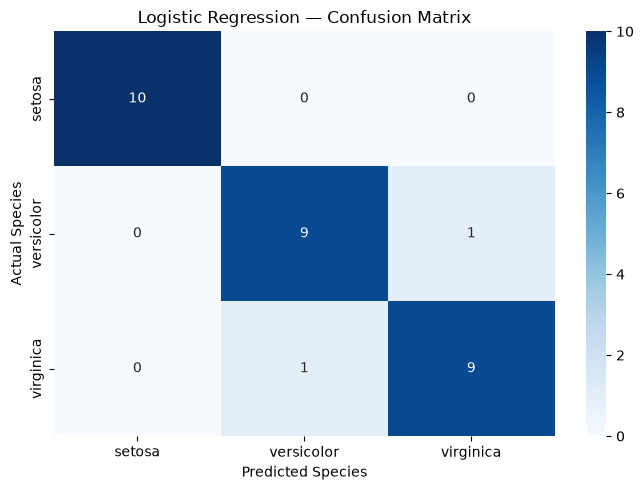

In [56]:
cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=Logistic_pipeline.classes_
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=Logistic_pipeline.classes_,
    yticklabels=Logistic_pipeline.classes_
)

plt.title("Logistic Regression — Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.tight_layout()
plt.show()

Logistic Regression Confusion Matrix Analysis


The confusion matrix shows that all Setosa samples were classified correctly. The model made two classification errors in total. One Versicolor flower was predicted as Virginica, and one Virginica flower was predicted as Versicolor. This aligns with the exploratory analysis, which indicated some overlap between Versicolor and Virginica, while Setosa was clearly separated from the other classes.

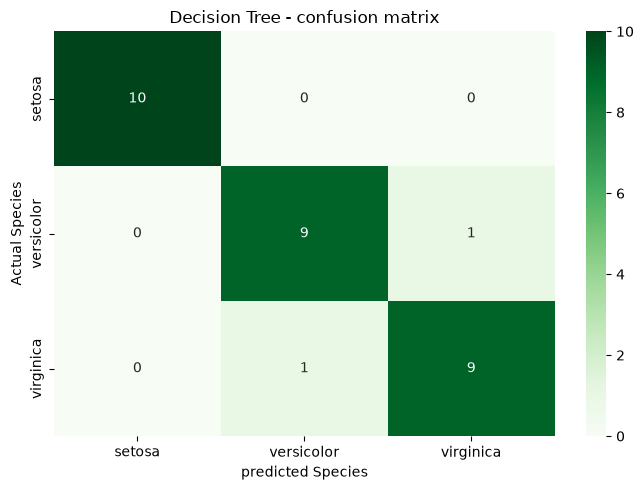

In [58]:
cm_tree = confusion_matrix(
    y_test,
    y_pred_tree,
    labels=tree_pipeline.classes_
)
plt.figure(figsize=(7,5))
sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=tree_pipeline.classes_,
    yticklabels=tree_pipeline.classes_
)
plt.title("Decision Tree - confusion matrix")
plt.xlabel("predicted Species")
plt.ylabel("Actual Species")
plt.tight_layout()
plt.show()

Engineering Conclusion


Both Logistic Regression and Decision Tree achieved 93% test accuracy on the Iris dataset. Setosa was classified perfectly, while small classification errors occurred between Versicolor and Virginica due to overlapping feature distributions. Based on this train-test split, both models performed similarly. However, the test set contains only 30 samples, so small differences in performance should be interpreted carefully. A larger evaluation such as cross-validation would provide a more reliable comparison.

In [61]:
from sklearn.metrics import accuracy_score

# Logistic Regression
Logistic_train_pred = Logistic_pipeline.predict(X_train)
logistic_test_pred = Logistic_pipeline.predict(X_test)

# Decision Tree
tree_train_pred = tree_pipeline.predict(X_train)
tree_test_pred = tree_pipeline.predict(X_test)

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Training Accuracy": [
        accuracy_score(y_train, Logistic_train_pred),
        accuracy_score(y_train, tree_train_pred)
    ],
    "Test Accuracy": [
        accuracy_score(y_test, logistic_test_pred),
        accuracy_score(y_test, tree_test_pred)
    ]
})

comparison.round(3)

,Model,Training Accuracy,Test Accuracy
0,Logistic Regression,0.958,0.933
1,Decision Tree,1.000,0.933


In [62]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

depths = [1, 2, 3, 4, 5, None]

tree_results = []

for depth in depths:
    pipeline = Pipeline([
        (
            "model",
            DecisionTreeClassifier(
                max_depth=depth,
                random_state=42
            )
        )
    ])

    pipeline.fit(X_train, y_train)

    train_predictions = pipeline.predict(X_train)
    test_predictions = pipeline.predict(X_test)

    tree_results.append({
        "Max Depth": depth,
        "Training Accuracy": accuracy_score(
            y_train, train_predictions
        ),
        "Test Accuracy": accuracy_score(
            y_test, test_predictions
        )
    })

depth_results_df = pd.DataFrame(tree_results)

depth_results_df.round(3)

,Max Depth,Training Accuracy,Test Accuracy
0,1.0,0.667,0.667
1,2.0,0.967,0.933
2,3.0,0.983,0.967
3,4.0,0.992,0.933
4,5.0,1.000,0.933
5,NaN,1.000,0.933


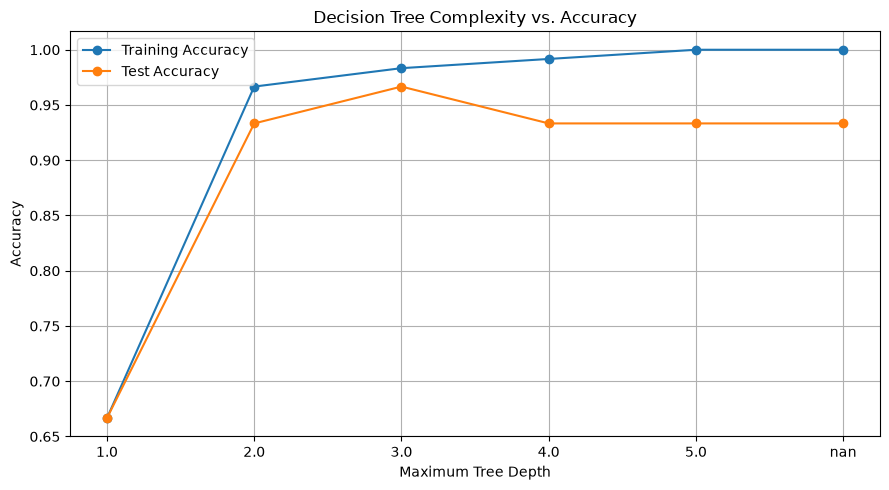

In [63]:
import matplotlib.pyplot as plt

plot_df = depth_results_df.copy()

plot_df["Max Depth"] = plot_df["Max Depth"].map(
    lambda depth: "Unlimited" if depth is None else str(depth)
)

plt.figure(figsize=(9, 5))

plt.plot(
    plot_df["Max Depth"],
    plot_df["Training Accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    plot_df["Max Depth"],
    plot_df["Test Accuracy"],
    marker="o",
    label="Test Accuracy"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree Complexity vs. Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [64]:
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

X_2d = df[["petal_length", "petal_width"]]
y_2d = df["species"]

X_2d_train, X_2d_test, y_2d_train, y_2d_test = train_test_split(
    X_2d,
    y_2d,
    test_size=0.2,
    random_state=42,
    stratify=y_2d
)

In [66]:
logistic_2d = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

tree_2d = Pipeline([
    ("model", DecisionTreeClassifier(random_state=42))
])

logistic_2d.fit(X_2d_train, y_2d_train)
tree_2d.fit(X_2d_train, y_2d_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['setosa','versicolor','virginica']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](2,)","['petal_length','petal_width']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'


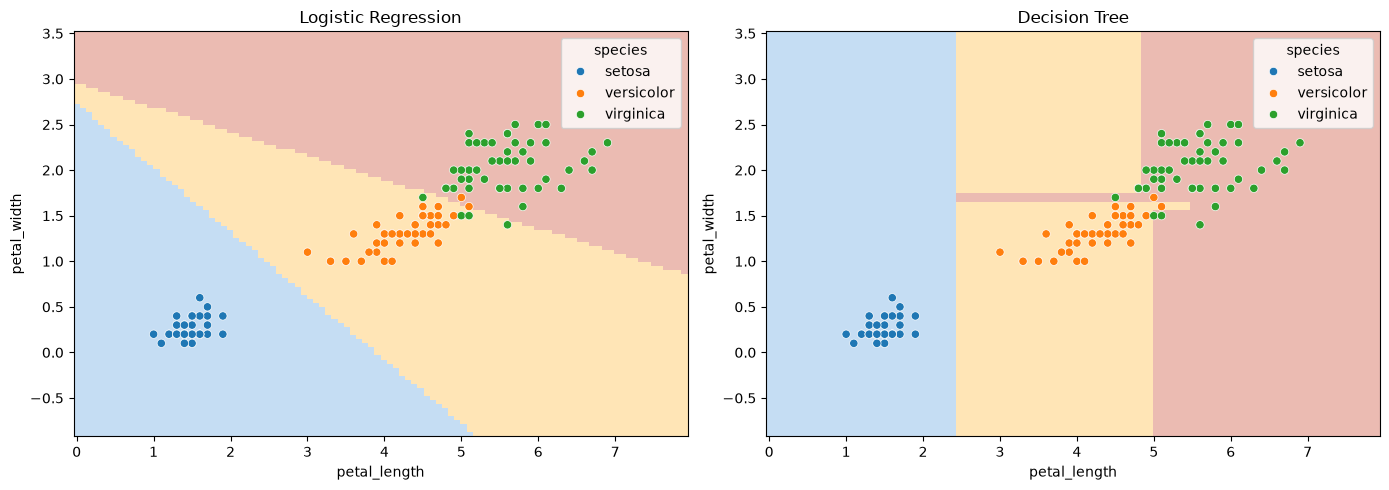

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models = [
    ("Logistic Regression", logistic_2d),
    ("Decision Tree", tree_2d)
]

for ax, (name, model) in zip(axes, models):
    DecisionBoundaryDisplay.from_estimator(
        model,
        X_2d,
        response_method="predict",
        plot_method="pcolormesh",
        shading="auto",
        alpha=0.3,
        ax=ax
    )

    sns.scatterplot(
        data=df,
        x="petal_length",
        y="petal_width",
        hue="species",
        ax=ax
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

In [68]:
plt.tight_layout()
plt.savefig(
    "../assets/decision_boundaries.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

<Figure size 640x480 with 0 Axes>

In [70]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

models = {
    "Logistic Regression": Logistic_pipeline,
    "Decision Tree": tree_pipeline
}

results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Macro)": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1-score (Macro)": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

results_df.round(3)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,Logistic Regression,0.933,0.933,0.933,0.933
1,Decision Tree,0.933,0.933,0.933,0.933


NameError: name 'logistic_pipeline' is not defined

In [72]:
for name, y_pred in predictions.items():
    print(f"\n{name}")
    print("-" * 50)

    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )


Logistic Regression
--------------------------------------------------
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Decision Tree
--------------------------------------------------
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



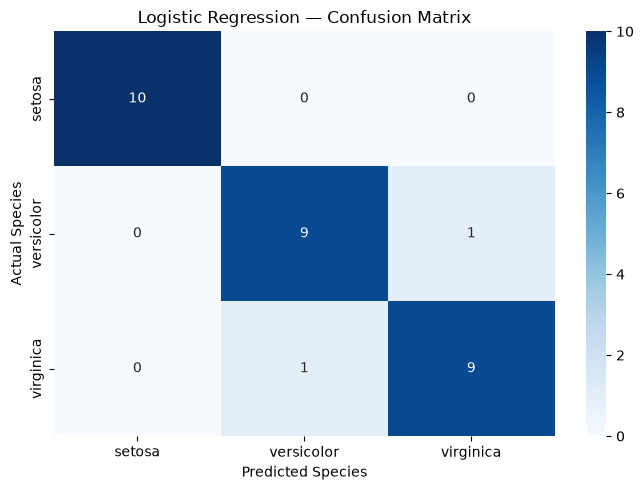

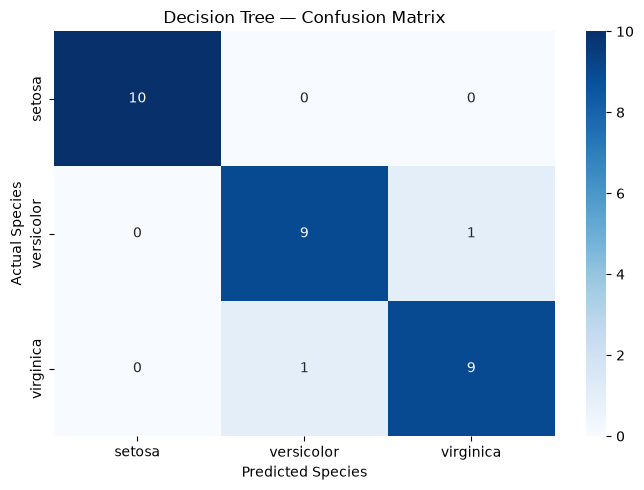

In [73]:
import matplotlib.pyplot as plt
import seaborn as sns

for name, model in models.items():
    y_pred = predictions[name]

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=model.classes_
    )

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=model.classes_,
        yticklabels=model.classes_
    )

    plt.title(f"{name} — Confusion Matrix")
    plt.xlabel("Predicted Species")
    plt.ylabel("Actual Species")
    plt.tight_layout()
    plt.show()

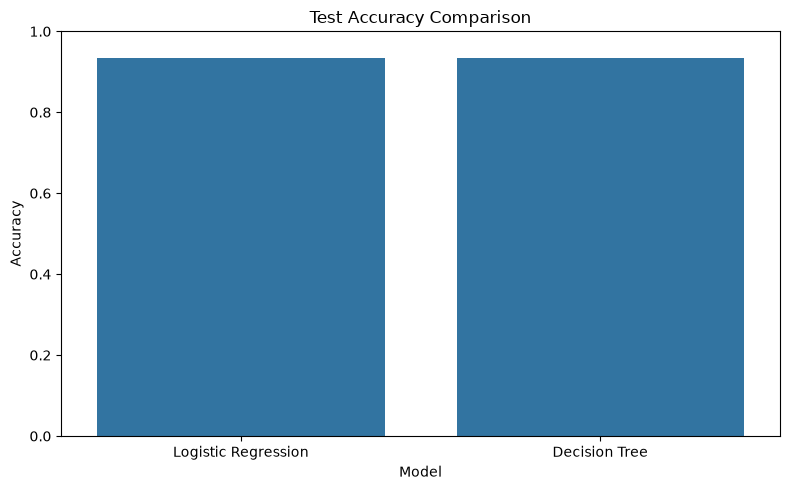

In [74]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.ylim(0, 1)
plt.title("Test Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.tight_layout()
plt.show()

In [75]:
plt.savefig(
    "accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

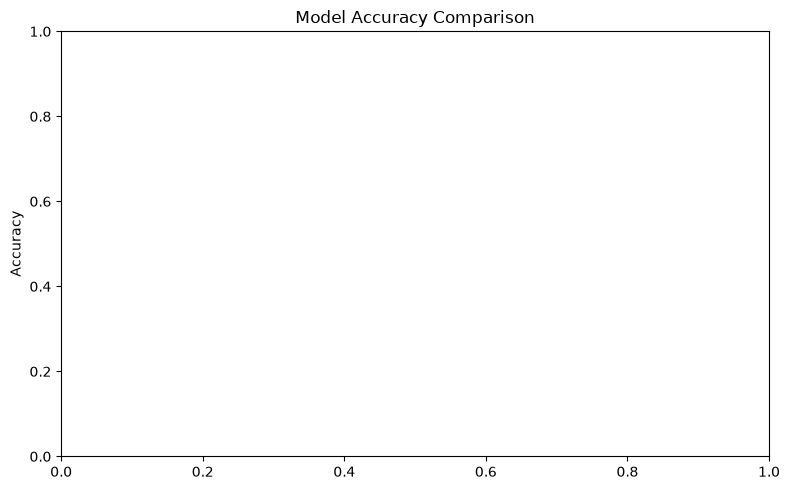

In [76]:
plt.figure(figsize=(8, 5))

# Your plotting code goes here.
# For example, create the bar chart using your results DataFrame.

plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.tight_layout()

plt.savefig(
    "../assets/accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [77]:
plt.tight_layout()

plt.savefig(
    "../assets/decision_boundaries.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 640x480 with 0 Axes>

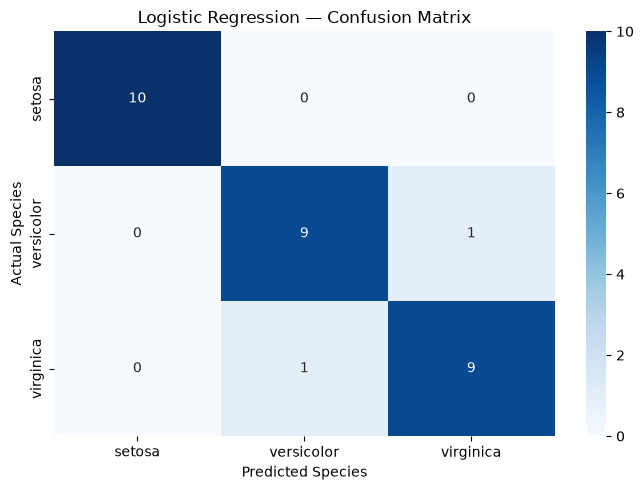

In [80]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=Logistic_pipeline.classes_
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=Logistic_pipeline.classes_,
    yticklabels=Logistic_pipeline.classes_
)

plt.title("Logistic Regression — Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.tight_layout()

plt.savefig(
    "../assets/logistic_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [82]:
plt.tight_layout()
plt.savefig(
    "../assets/decision_boundaries.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

<Figure size 640x480 with 0 Axes>

,Model,Training Accuracy,Test Accuracy
0,Logistic Regression,0.958,0.933
1,Decision Tree,1.000,0.933


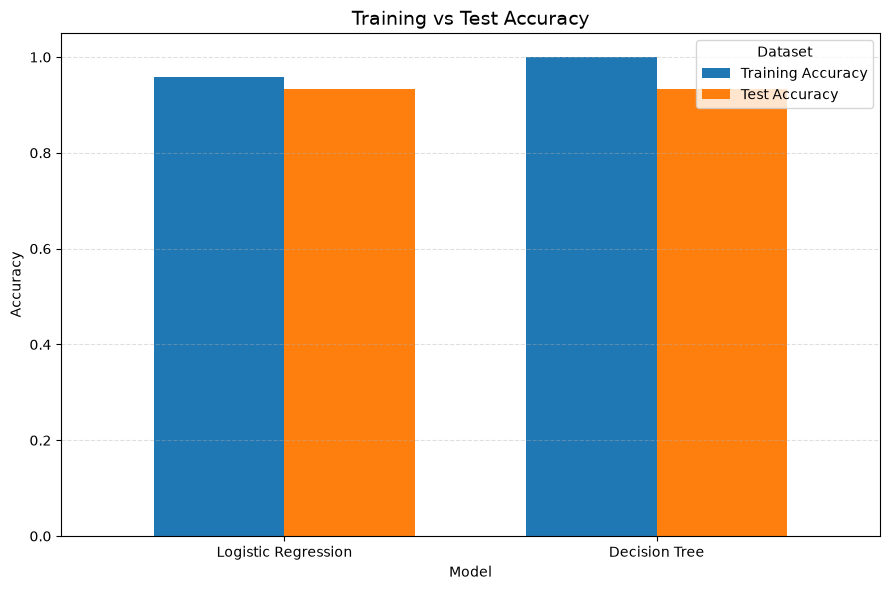

In [86]:

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import accuracy_score

# Calculate predictions for both models
logistic_train_pred = Logistic_pipeline.predict(X_train)
logistic_test_pred = Logistic_pipeline.predict(X_test)

tree_train_pred = tree_pipeline.predict(X_train)
tree_test_pred = tree_pipeline.predict(X_test)

# Calculate training and test accuracy
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Training Accuracy": [
        accuracy_score(y_train, logistic_train_pred),
        accuracy_score(y_train, tree_train_pred)
    ],
    "Test Accuracy": [
        accuracy_score(y_test, logistic_test_pred),
        accuracy_score(y_test, tree_test_pred)
    ]
})

# Display the numerical results
display(comparison.round(3))

# Create the chart
ax = comparison.set_index("Model").plot(
    kind="bar",
    figsize=(9, 6),
    width=0.7
)

ax.set_title("Training vs Test Accuracy", fontsize=14)
ax.set_xlabel("Model")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1.05)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(title="Dataset")
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

# Save the chart
plt.savefig(
    "../assets/accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
 


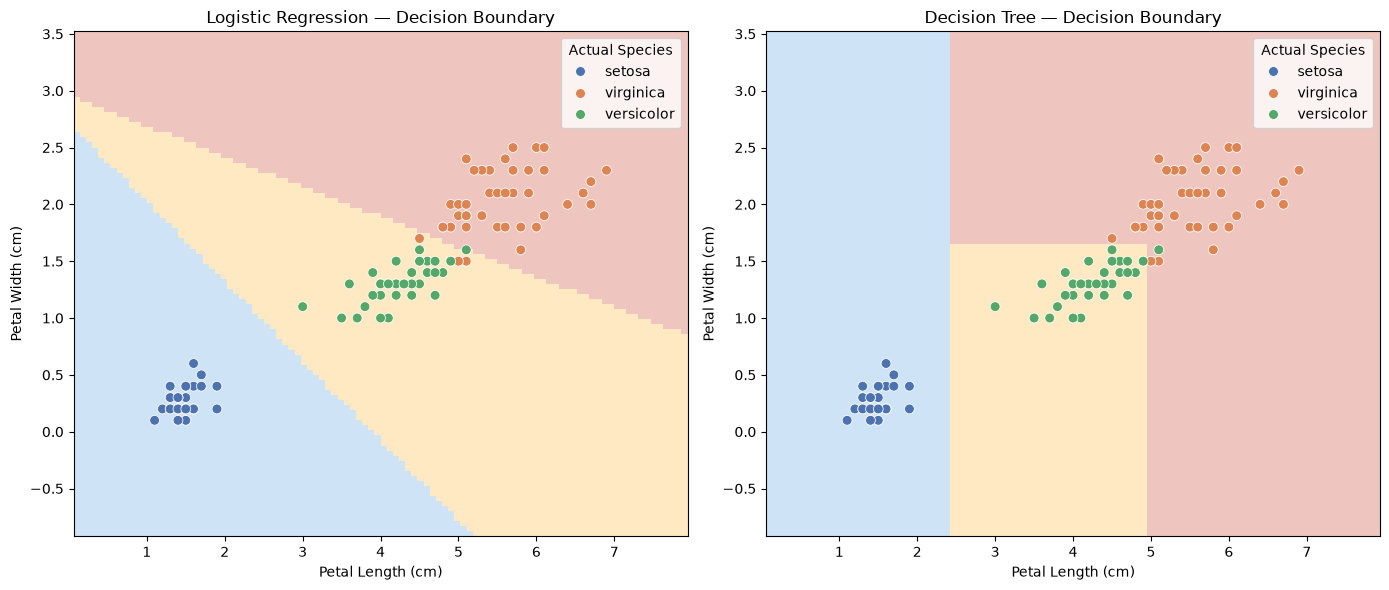

In [87]:

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import DecisionBoundaryDisplay

# Select only two features for visualization
X_2d = df[["petal_length", "petal_width"]]
y_2d = df["species"]

# Split the data
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d,
    y_2d,
    test_size=0.2,
    random_state=42,
    stratify=y_2d
)

# Define models for the two-feature visualization
models_2d = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        max_depth=3
    )
}

# Train both models using only the two selected features
for model in models_2d.values():
    model.fit(X_train_2d, y_train_2d)

# Create two plots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (name, model) in zip(axes, models_2d.items()):

    # Draw the decision regions
    DecisionBoundaryDisplay.from_estimator(
        model,
        X_train_2d,
        response_method="predict",
        plot_method="pcolormesh",
        shading="auto",
        alpha=0.25,
        ax=ax
    )

    # Overlay the actual training observations
    sns.scatterplot(
        data=df.loc[X_train_2d.index],
        x="petal_length",
        y="petal_width",
        hue="species",
        palette="deep",
        s=50,
        ax=ax,
        legend=True
    )

    ax.set_title(f"{name} — Decision Boundary")
    ax.set_xlabel("Petal Length (cm)")
    ax.set_ylabel("Petal Width (cm)")

    ax.legend(title="Actual Species")

plt.tight_layout()

# Save both plots together
plt.savefig(
    "../assets/decision_boundaries.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
 
